# Using the pulse dataset loaders

Six short examples:

1. Loading the raw data using the SimpePulseDataset class
2. Viewing the raw data
3. Exploiting different ADC views of one physical pulse
4. SNR degradation using the AugmentedPulseDataset wrapper class
5. CFO and phase correction using the AugmentedPulseDataset wrapper class

In [11]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch
from collections import Counter
from torch.utils.data import DataLoader, Subset
from scipy.signal import spectrogram

from dataloaders.dataloader import SimplePulseDataset, AugmentedPulseDataset   # change to your module name

## 1. Loading the raw data using the SimpePulseDataset class

`adc_names` is required: pass at least one ADC. Other useful arguments: `blade_filter`, `max_pulses_per_emitter=N`
(at most N pulses per emitter) and `load_to_memory=True` (cache every pulse in RAM: faster training but needs more memory).

The script will 

This may take a while to load depending on the settings used.

In [12]:
ds = SimplePulseDataset(
    hdf5_dir="./data", 
    load_to_memory=True,
    max_pulses_per_emitter=1000,
    adc_names=["adc0", "adc2", "adc4", "adc6"],
    adc_mode="single",
    day_filter=["day1"],
    environment_filter=["chamber"],
    temp_filter=["cold"],
    blade_filter=None,
    waveform_filter=["chirp"],
    return_pdw=True
)

print("\nBladeRF emitters and pulse counts:", dict(sorted(Counter(e["labels"]["emitter"] for e in ds.pulse_index).items())))

# This should report "ADC0", "ADC2", "ADC4", "ADC6" and then repeat.
print(f"\n{len(ds)} items = {len(ds.pulse_index)} pulses x {len(ds.adc_names)} ADCs")
print("first eight signals come from:", [ds[i][1]["adc"] for i in range(8)])

# one item = (pulse, labels, pdw); pdw only returned if return_pdw=True
pulse, labels, pdw = ds[0]          
print("\npulse :", tuple(pulse.shape), "= (samples, [I, Q])")
print("labels:", labels)
print("pdw fields:", sorted(pdw))

Dataset: 12000 groups x 4 ADCs (0 unmatched, 2 below 31 dB dropped)
Loading all data to memory...
Loaded 12000 entries to memory

BladeRF emitters and pulse counts: {'blade1': 1000, 'blade10': 1000, 'blade11': 1000, 'blade12': 1000, 'blade2': 1000, 'blade3': 1000, 'blade4': 1000, 'blade5': 1000, 'blade6': 1000, 'blade7': 1000, 'blade8': 1000, 'blade9': 1000}

48000 items = 12000 pulses x 4 ADCs
first eight signals come from: ['adc0', 'adc2', 'adc4', 'adc6', 'adc0', 'adc2', 'adc4', 'adc6']

pulse : (8192, 2) = (samples, [I, Q])
labels: {'day': 'day1', 'environment': 'chamber', 'temp': 'cold', 'emitter': 'blade1', 'pulse_type': 'chirp', 'adc': 'adc0'}
pdw fields: ['bandwidth', 'centre_frequency', 'dead_time', 'noise_floor', 'pulse_id', 'pulse_power', 'pulse_width', 'snr', 'start_frequency', 'stop_frequency', 'time_of_arrival']


#### We can also print the total number of pulses in the dataset to see if it matches our expected breakdown. 

If all `adc_names` ("adc0", "adc2", "adc4", "adc6") are used with `blade_filter` set to "None", `max_pulses_per_emitter` set to 1000 for the "day1 cold" dataset, we expect 48000 raw pulses. (12 Emitters * 4 ADCs * 1000 Pulses each)

In [13]:
print("\ndataset length (total number of pulses):", len(ds))


dataset length (total number of pulses): 48000


## 2. Viewing the raw data

reported SNR 40.4 dB, time of arrival 0.0008639333536848426


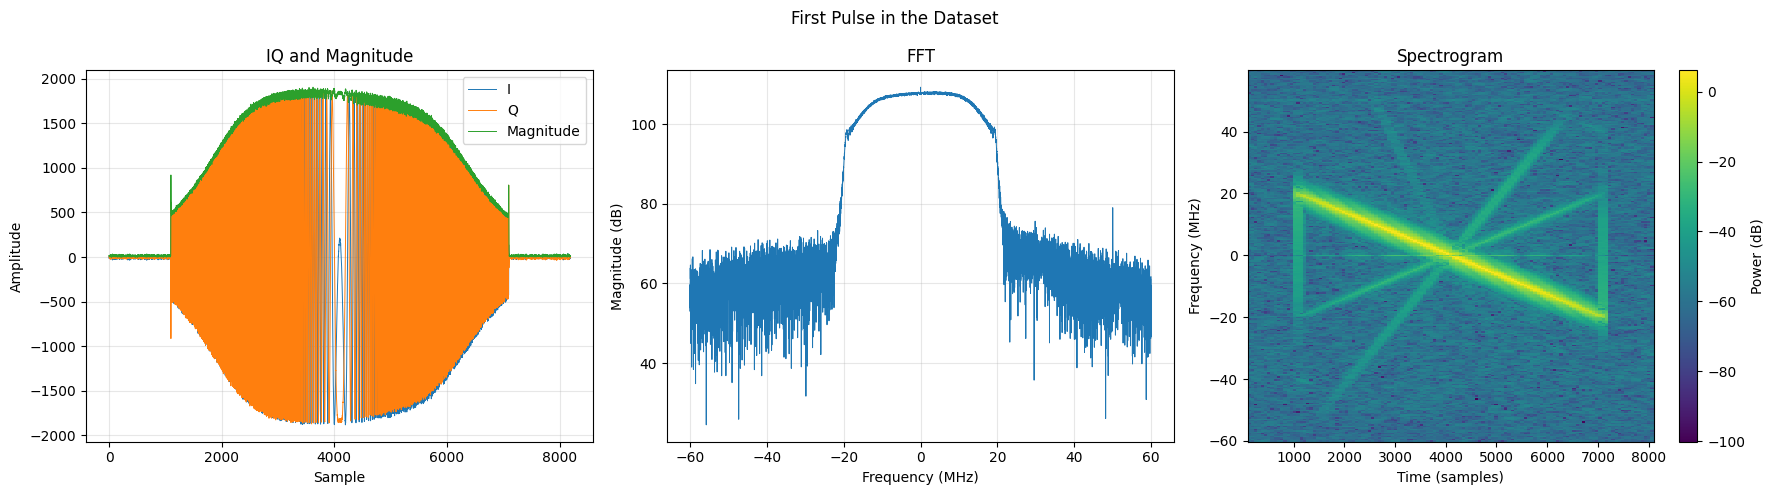

In [14]:
pulse, labels, pdw = ds[0]

# Pull sample rate from meta-data, we only need to do this once as it is fixed in the dataset.
fs = float(ds.get_metadata(0)["sample_rate"])

iq = np.asarray(pulse)
print(f"reported SNR {float(pdw['snr']):.1f} dB, time of arrival {pdw['time_of_arrival']}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. IQ and Magnitude
axes[0].plot(iq[:, 0], lw=0.7, label="I")
axes[0].plot(iq[:, 1], lw=0.7, label="Q")
axes[0].plot(np.hypot(iq[:, 0], iq[:, 1]), lw=0.7, label="Magnitude")
axes[0].set_title("IQ and Magnitude")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. FFT
complex_iq = iq[:, 0] + 1j * iq[:, 1]

fft_data = np.fft.fftshift(np.fft.fft(complex_iq))
freq = np.fft.fftshift(
    np.fft.fftfreq(len(complex_iq), d=1/fs)
)

axes[1].plot(freq / 1e6, 20 * np.log10(np.abs(fft_data) + 1e-12), lw=0.7)
axes[1].set_title("FFT")
axes[1].set_xlabel("Frequency (MHz)")
axes[1].set_ylabel("Magnitude (dB)")
axes[1].grid(True, alpha=0.3)

# 3. Spectrogram
f, t, Sxx = spectrogram(
    complex_iq,
    fs=fs,
    nperseg=256,
    noverlap=192,
    return_onesided=False,
    mode="magnitude"
)

# Centre zero frequency
Sxx = np.fft.fftshift(Sxx, axes=0)
f = np.fft.fftshift(f)

im = axes[2].pcolormesh(
    t * fs,                   # Time in samples
    f / 1e6,                  # Frequency in MHz
    20 * np.log10(Sxx + 1e-12),
    shading="auto",
    cmap="viridis"
)

axes[2].set_title("Spectrogram")
axes[2].set_xlabel("Time (samples)")
axes[2].set_ylabel("Frequency (MHz)")

fig.colorbar(im, ax=axes[2], label="Power (dB)")

fig.suptitle("First Pulse in the Dataset")
plt.tight_layout()
plt.show()

## 3. Exploiting different ADC views of one physical pulse

`adc_mode="contrastive"`: one item is every ADC's view of the **same physical pulse**, matched by time of arrival.

In this example, we instead inspect the `pulse` waveform.

Dataset: 12000 groups x 4 ADCs (0 unmatched, 1 below 31 dB dropped)
Loading all data to memory...
Loaded 12000 entries to memory
12000 physical pulses; one item = (4, 8192, 2) = (ADC, samples, [I, Q])

time-of-arrival spread across ADCs 0.00e+00  (matching tolerance 2e-06)
  adc0: reported SNR 41.1 dB
  adc2: reported SNR 41.3 dB
  adc4: reported SNR 45.0 dB
  adc6: reported SNR 39.9 dB


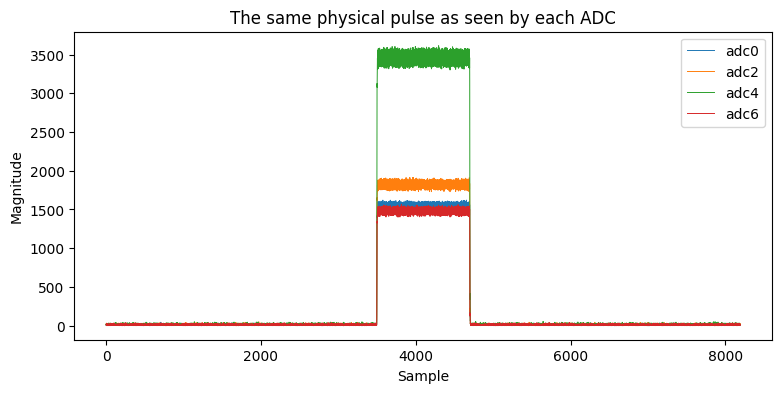

In [15]:
stacked = SimplePulseDataset(
    hdf5_dir="./data", 
    load_to_memory=True,
    max_pulses_per_emitter=1000,
    adc_names=["adc0", "adc2", "adc4", "adc6"],
    adc_mode="contrastive",
    day_filter=["day1"],
    environment_filter=["chamber"],
    temp_filter=["cold"],
    blade_filter=None,
    waveform_filter=["pulse"],
    return_pdw=True
)
pulses, labels, pdws = stacked[0]

print(f"{len(stacked)} physical pulses; one item = {tuple(pulses.shape)} = (ADC, samples, [I, Q])")
toas = [float(p["time_of_arrival"]) for p in pdws]
print(f"\ntime-of-arrival spread across ADCs {max(toas) - min(toas):.2e}  (matching tolerance {stacked.TOA_TOLERANCE:.0e})")
for adc, p in zip(stacked.adc_names, pdws):
    print(f"  {adc}: reported SNR {float(p['snr']):.1f} dB")

fig, ax = plt.subplots(figsize=(9, 4))

for adc, view in zip(stacked.adc_names, np.asarray(pulses)):
    magnitude = np.hypot(view[:, 0], view[:, 1])
    ax.plot(magnitude, lw=0.7, label=adc)

ax.set_title(f"The same physical pulse as seen by each ADC")
ax.set_xlabel("Sample")
ax.set_ylabel("Magnitude")
ax.legend()

plt.show()

`adc_mode="single"` (the default) instead gives every ADC view as its own item, labelled with its ADC.
Pulses with a reported SNR below 31 dB on **any** requested ADC are dropped, so counts can be lower than the files hold to reduce memory requirements (or make the challenge more difficult)

## 4. SNR degradation using the AugmentedPulseDataset wrapper class

`AugmentedPulseDataset` wraps a base `SimplePulseDataset` dataset class and degrades each pulse to a target SNR. Every base pulse appears once per
target SNR, ordered pulse-major: `aug[k * len(SNRS) + j]` is base pulse `k` at `SNRS[j]`.

If the requested SNR is set to `"NA"` as used below, no SNR augmentation occurs.

48000 base pulses -> 240000 items (5 target SNRs each)


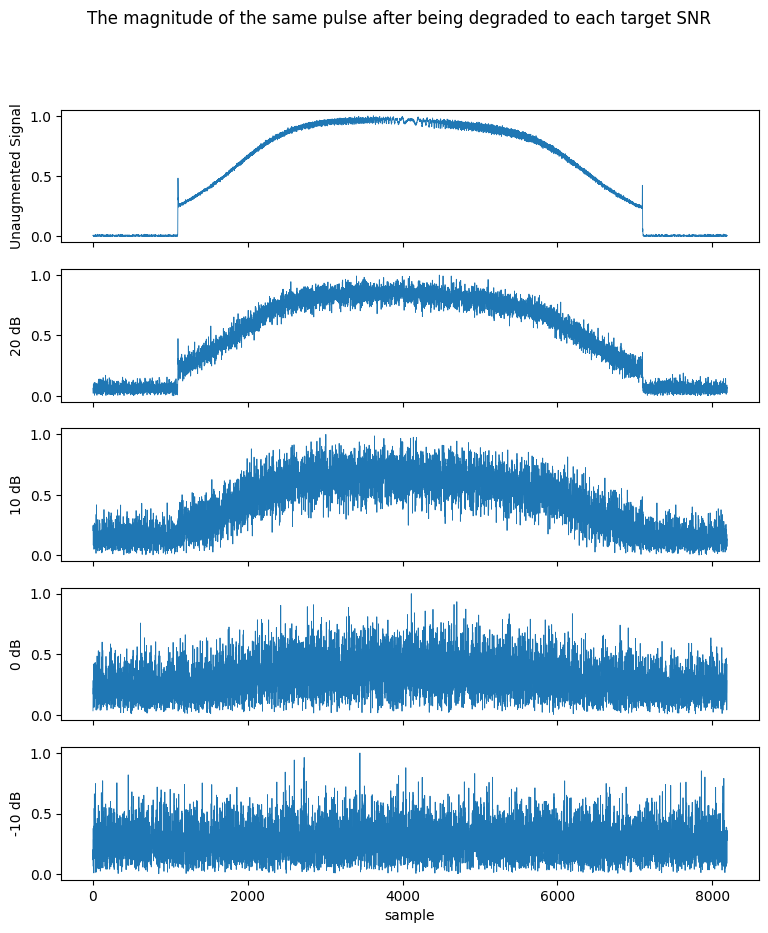

In [16]:
SNRs = ["NA", 20, 10, 0, -10]

# In this case, we wrap the "AugmentedPulseDataset" around our previous dataset from example 1
aug = AugmentedPulseDataset(ds, 
                            target_snrs_db=SNRs,
                            add_magnitude=True,
                            normalise=True
                           )

print(f"{len(ds)} base pulses -> {len(aug)} items ({len(SNRs)} target SNRs each)")

fig, axes = plt.subplots(len(SNRs), 1, sharex=True, sharey=False, figsize=(9, 2 * len(SNRs)))
for j, (ax, target) in enumerate(zip(axes, SNRs)):
    pulse, labels = aug[j]                     
    ax.plot(np.asarray(pulse)[2], lw=0.6)      # pulse is (3, samples) = [I, Q, magnitude]; channel 2 is the magnitude
    if target == "NA":
        ax.set_ylabel(f"Unaugmented Signal")
    else:
        ax.set_ylabel(f"{target} dB")
    
axes[-1].set_xlabel("sample")
fig.suptitle("The magnitude of the same pulse after being degraded to each target SNR")
plt.show()

The same method also works when `AugmentedPulseDataset` wraps a base `SimplePulseDataset` where `mode="contrastive"`:

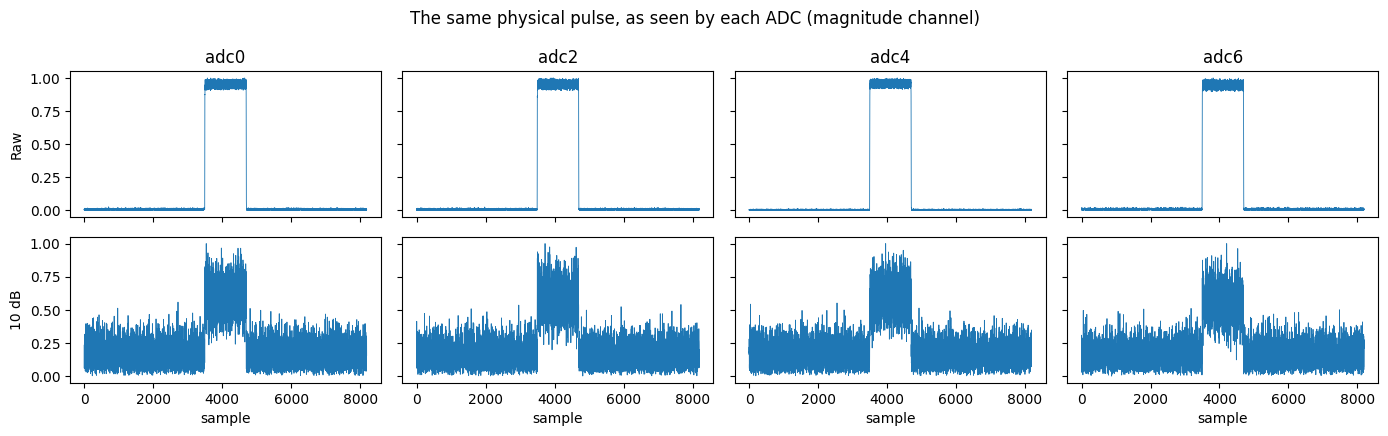

In [17]:
SNRs = ["NA", 10]

aug_stack = AugmentedPulseDataset(stacked,
                                  target_snrs_db=SNRs,
                                  add_magnitude=True,
                                  normalise=True,
                                  mode="contrastive"
                                 )

pulses, labels = aug_stack[0]       # (n_adc * n_snr, 3, samples), ordered ADC first, then SNR
views = np.asarray(pulses).reshape(len(stacked.adc_names), len(SNRs), 3, -1)   # (ADC, SNR, channel, samples)

fig, axes = plt.subplots(len(SNRs), len(stacked.adc_names), sharex=True, sharey="row", figsize=(14, 2.2 * len(SNRs)))
for a, adc in enumerate(stacked.adc_names):
    for s, target in enumerate(SNRs):
        ax = axes[s, a]
        ax.plot(views[a, s, 2], lw=0.6)                    # channel 2 is the magnitude
        if s == 0:
            ax.set_title(adc)
        if a == 0:
            ax.set_ylabel("Raw" if target == "NA" else f"{target} dB")
for ax in axes[-1]:
    ax.set_xlabel("sample")
fig.suptitle("The same physical pulse, as seen by each ADC (magnitude channel)")
plt.tight_layout()
plt.show()

## 5. CFO and phase correction using the AugmentedPulseDataset wrapper class

`correct_cfo=True` removes each pulse's measured centre-frequency offset. `correct_phase=True` rotates each pulse onto a fixed reference pulse, so pulses from different captures line up. The reference is found in the data folder, regardless of what dataset filters are used, so training, testing and every evaluation share it.

The example below takes 4 pulses (from 4 ADCs) and shows the I and Q before (left-hand side) and after (right-hand side) centre-frequency and phase correction.

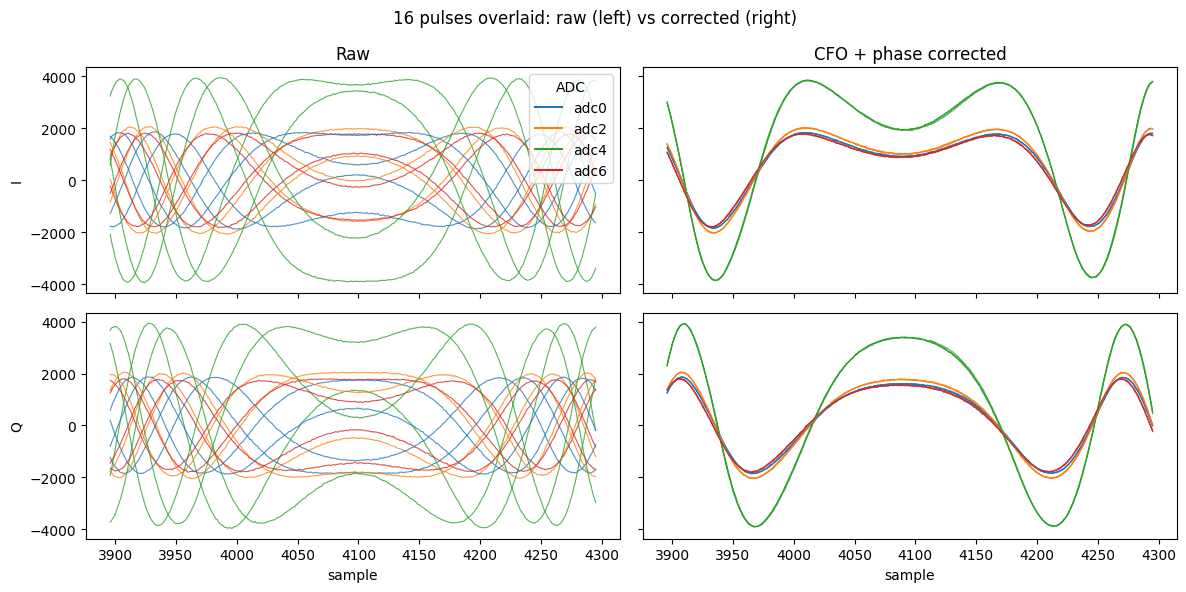

phase reference pulse comes from: data/day1_chamber_cold_blade10_chirp_adc0_chunk_0.h5


In [18]:
N = 16     # items to overlay. Consecutive items are the ADCs' views of one physical pulse: 16 items = 4 pulses x 4 ADCs

raw = AugmentedPulseDataset(ds, target_snrs_db=["NA"])
corrected = AugmentedPulseDataset(ds, target_snrs_db=["NA"], correct_cfo=True, correct_phase=True)

def read(dataset, i):
    pulse, labels = dataset[i]
    return np.asarray(pulse), labels["adc"]          # pulse is (samples, [I, Q])

raw_items = [read(raw, i) for i in range(N)]
cor_items = [read(corrected, i) for i in range(N)]

c = len(raw_items[0][0]) // 2
window = slice(c - 200, c + 200)                     # zoom on the middle 400 samples
colours = {adc: f"C{k}" for k, adc in enumerate(ds.adc_names)}

fig, axes = plt.subplots(2, 2, sharex=True, sharey="row", figsize=(12, 6))
for col, (items, title) in enumerate(((raw_items, "Raw"), (cor_items, "CFO + phase corrected"))):
    for iq, adc in items:
        x = np.arange(len(iq))[window]
        axes[0, col].plot(x, iq[window, 0], color=colours[adc], lw=0.8, alpha=0.8)      # I
        axes[1, col].plot(x, iq[window, 1], color=colours[adc], lw=0.8, alpha=0.8)      # Q
    axes[0, col].set_title(title)
    axes[1, col].set_xlabel("sample")
axes[0, 0].set_ylabel("I")
axes[1, 0].set_ylabel("Q")
axes[0, 0].legend(handles=[plt.Line2D([], [], color=col, label=adc) for adc, col in colours.items()], title="ADC", loc="upper right")
fig.suptitle(f"{N} pulses overlaid: raw (left) vs corrected (right)")
plt.tight_layout()
plt.show()

print("phase reference pulse comes from:", corrected.anchor_file)